In [1]:
# Step 1: Import the required libraries

import cv2
import numpy as np
import matplotlib.pyplot as plt

Saving EAGLE.jpg to EAGLE.jpg


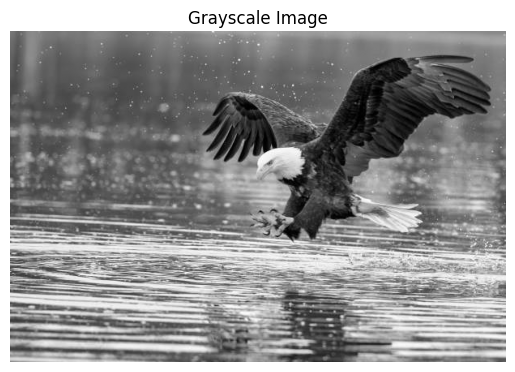

In [2]:
# Step 2: Load a grayscale image

from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

image = cv2.imread(image_path)

if image is None:
    print("Error: Image not found.")
else:
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    plt.imshow(gray_image, cmap="gray")
    plt.title("Grayscale Image")
    plt.axis("off")
    plt.show()

/tmp/ipykernel_1718/2848231037.py:11: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(gray_image.ravel(), 256, [0, 256])


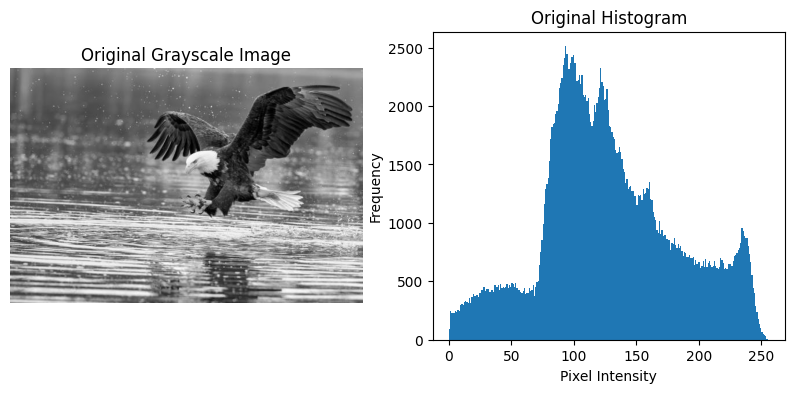

In [3]:
# Step 3: Display the original image and generate its histogram

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.hist(gray_image.ravel(), 256, [0, 256])
plt.title("Original Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.show()

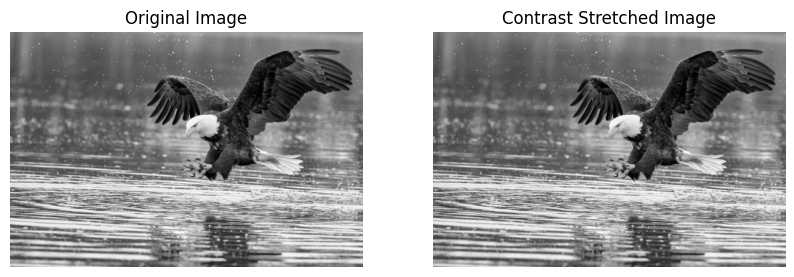

In [4]:
# Step 4: Perform contrast stretching

min_intensity = np.min(gray_image)
max_intensity = np.max(gray_image)

contrast_stretched = ((gray_image - min_intensity) /
                      (max_intensity - min_intensity) * 255)

contrast_stretched = np.uint8(contrast_stretched)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(contrast_stretched, cmap="gray")
plt.title("Contrast Stretched Image")
plt.axis("off")

plt.show()

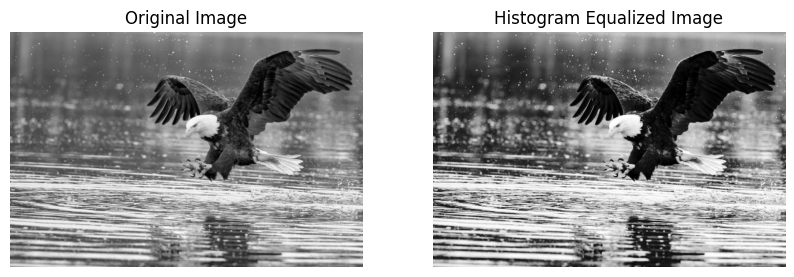

In [5]:
# Step 5: Apply Histogram Equalization

equalized_image = cv2.equalizeHist(gray_image)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(equalized_image, cmap="gray")
plt.title("Histogram Equalized Image")
plt.axis("off")

plt.show()

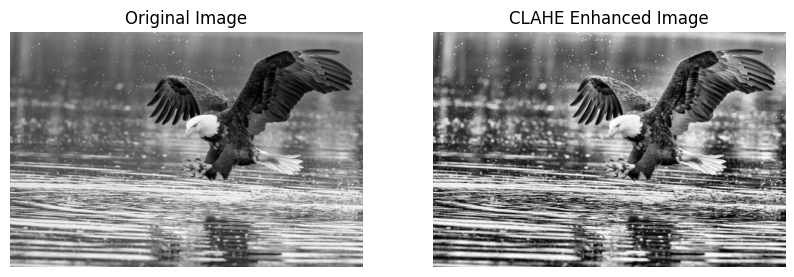

In [6]:
# Step 6: Apply CLAHE

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

clahe_image = clahe.apply(gray_image)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(clahe_image, cmap="gray")
plt.title("CLAHE Enhanced Image")
plt.axis("off")

plt.show()

/tmp/ipykernel_1718/2196705656.py:6: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(gray_image.ravel(), 256, [0, 256])
/tmp/ipykernel_1718/2196705656.py:12: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(equalized_image.ravel(), 256, [0, 256])
/tmp/ipykernel_1718/2196705656.py:18: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(clahe_image.ravel(), 256, [0, 256])


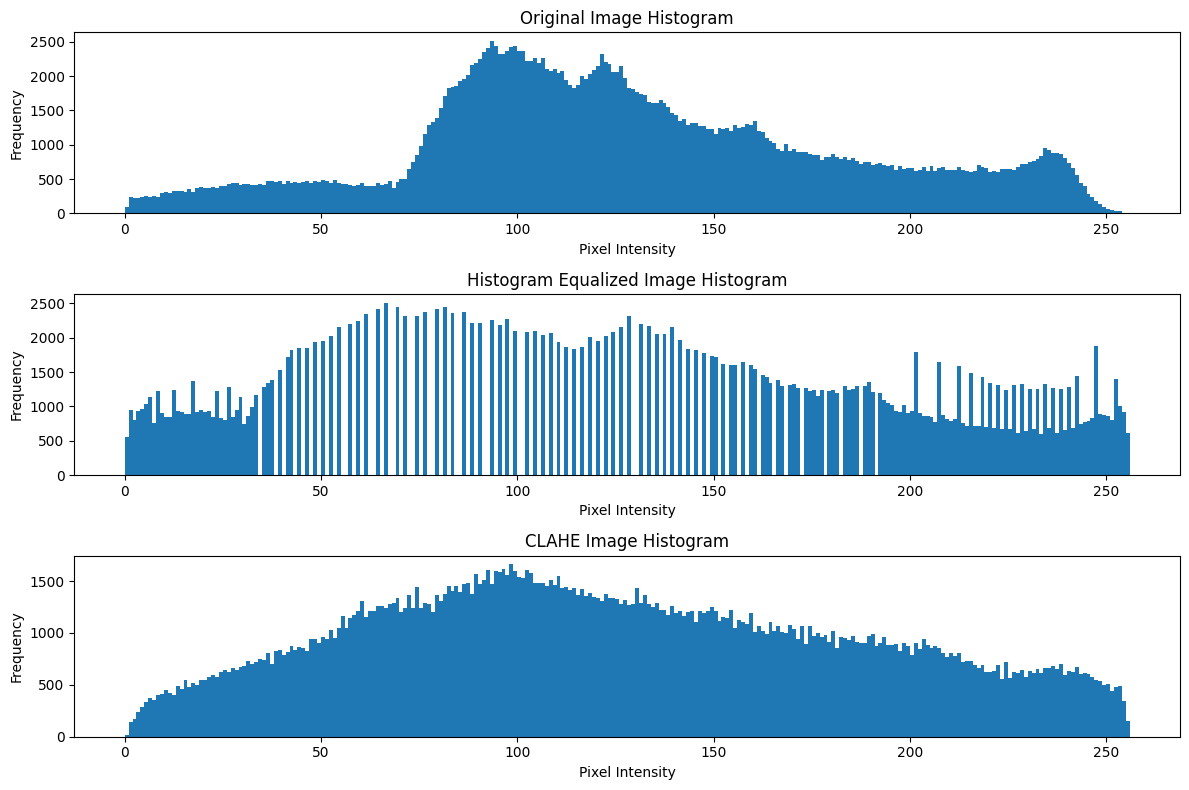

In [7]:
# Step 7: Plot and compare the histograms

plt.figure(figsize=(12, 8))

plt.subplot(3, 1, 1)
plt.hist(gray_image.ravel(), 256, [0, 256])
plt.title("Original Image Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.subplot(3, 1, 2)
plt.hist(equalized_image.ravel(), 256, [0, 256])
plt.title("Histogram Equalized Image Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.subplot(3, 1, 3)
plt.hist(clahe_image.ravel(), 256, [0, 256])
plt.title("CLAHE Image Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

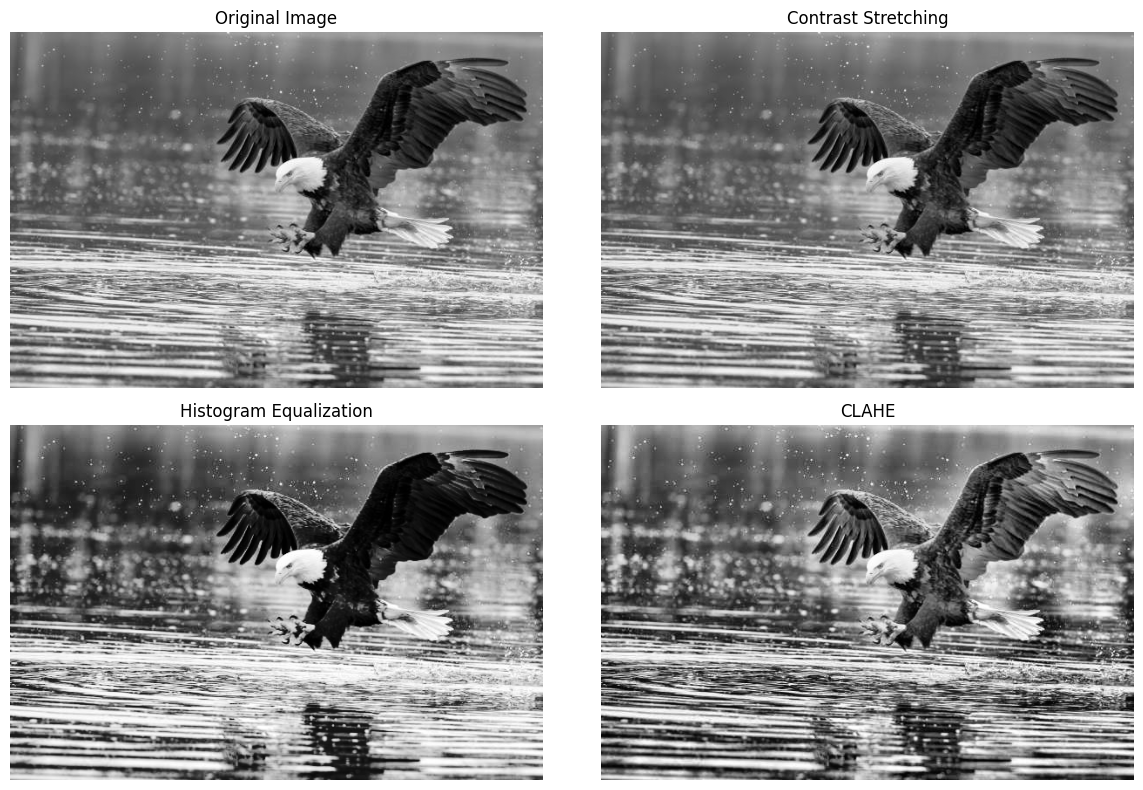

In [8]:
# Step 8: Analyze visual improvements

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(contrast_stretched, cmap="gray")
plt.title("Contrast Stretching")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(equalized_image, cmap="gray")
plt.title("Histogram Equalization")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(clahe_image, cmap="gray")
plt.title("CLAHE")
plt.axis("off")

plt.tight_layout()
plt.show()

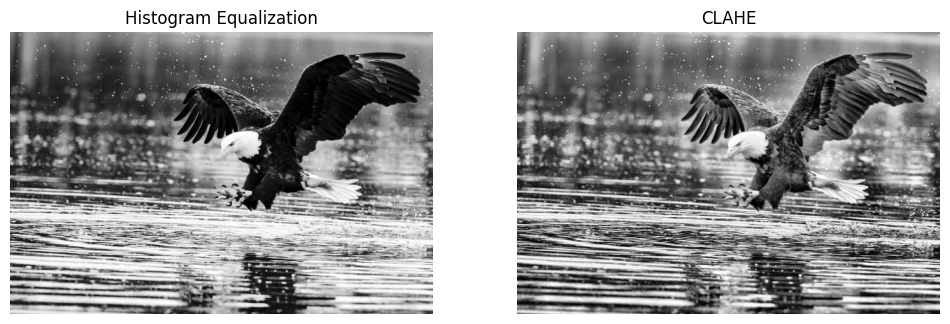

Histogram Equalization improves the overall contrast of the image.
CLAHE improves local contrast and performs better under varying illumination.


In [9]:
# Step 9: Compare Histogram Equalization and CLAHE

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(equalized_image, cmap="gray")
plt.title("Histogram Equalization")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(clahe_image, cmap="gray")
plt.title("CLAHE")
plt.axis("off")

plt.show()

print("Histogram Equalization improves the overall contrast of the image.")
print("CLAHE improves local contrast and performs better under varying illumination.")

In [10]:
# Step 10: Save enhanced images

cv2.imwrite("contrast_stretched.jpg", contrast_stretched)
cv2.imwrite("histogram_equalized.jpg", equalized_image)
cv2.imwrite("clahe_enhanced.jpg", clahe_image)

print("All enhanced images have been saved successfully.")

All enhanced images have been saved successfully.
